# Algoritmia y Optimización — Ejercicios

Notebook con la implementación, experimentos, gráficas y análisis de los 5 ejercicios:

1. Aceleración paralela (`estimate_pi` con 1, 2, 4 y 8 procesos)
2. Mochila voraz: criterio de menor peso vs. valor/peso
3. Búsqueda local 2-opt para TSP (inicio aleatorio vs. Vecino Más Cercano)
4. Recocido Simulado (esquemas de enfriamiento)
5. Razón de aproximación del algoritmo basado en MST

Todas las figuras se guardan en la carpeta `figures/`. Las semillas están fijas para que los resultados
combinatorios (ejercicios 2, 3, 4 y 5) sean reproducibles; los **tiempos** (ejercicios 1 y 4) dependen de la máquina.

In [1]:
import os, time, math, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

os.makedirs("figures", exist_ok=True)
SEED = 440
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

# ---------- utilidades compartidas por los ejercicios de TSP (3, 4 y 5) ----------
def dist_matrix(pts):
    diff = pts[:, None, :] - pts[None, :, :]
    return np.sqrt((diff ** 2).sum(-1))

def tour_length(tour, D):
    tour = np.asarray(tour)
    return float(D[tour, np.roll(tour, -1)].sum())

def nearest_neighbor(D, start):
    n = len(D)
    visited = np.zeros(n, bool)
    tour = [start]; visited[start] = True
    for _ in range(n - 1):
        d = np.where(visited, np.inf, D[tour[-1]])
        nxt = int(np.argmin(d))
        tour.append(nxt); visited[nxt] = True
    return np.array(tour)

def two_opt(tour, D, strategy="first"):
    """2-opt hasta optimo local.
    strategy='first': aplica la primera mejora que encuentra (en orden i<j).
    strategy='best' : aplica la mejor mejora de todo el vecindario.
    Devuelve (tour, numero_de_mejoras, historial_de_longitudes)."""
    t = np.array(tour); n = len(t)
    I, J = np.triu_indices(n, k=2)                 # pares i<j no adyacentes, en orden de barrido
    keep = ~((I == 0) & (J == n - 1))              # (0, n-1) comparten arista en el ciclo
    I, J = I[keep], J[keep]
    L = tour_length(t, D); hist = [L]; improvements = 0
    while True:
        a, b, c, d = t[I], t[I + 1], t[J], t[(J + 1) % n]
        delta = D[a, c] + D[b, d] - D[a, b] - D[c, d]   # cambio de costo al reemplazar (a,b),(c,d) por (a,c),(b,d)
        if strategy == "first":
            idx = np.flatnonzero(delta < -1e-12)
            if idx.size == 0: break
            k = idx[0]
        else:
            k = int(np.argmin(delta))
            if delta[k] >= -1e-12: break
        i, j = I[k], J[k]
        t[i + 1:j + 1] = t[i + 1:j + 1][::-1].copy()    # invierte el segmento
        L += delta[k]; hist.append(L); improvements += 1
    return t, improvements, np.array(hist)

---
## Ejercicio 1 — Aceleración paralela (Parallel Speedup)

`estimate_pi` estima π por Monte Carlo: se lanzan `N` puntos uniformes en el cuadrado unitario y
$\pi \approx 4\cdot\#\{x^2+y^2\le 1\}/N$. Con `p` procesos, el trabajo total `N` (**fijo**, *strong scaling*) se reparte en `p`
bloques independientes, cada uno con su propio generador (`SeedSequence.spawn`), y al final se suman los conteos.

La función de trabajo vive en un módulo aparte (`pi_worker.py`) porque en macOS/Windows `multiprocessing` usa *spawn*
y los procesos hijos necesitan poder importarla.

In [2]:
%%writefile pi_worker.py
import numpy as np

def count_inside(args):
    """Cuenta cuantos de `n` puntos aleatorios caen dentro del cuarto de circulo."""
    n, seed = args
    rng = np.random.default_rng(seed)
    inside, done, chunk = 0, 0, 2_000_000
    while done < n:
        m = min(chunk, n - done)
        x, y = rng.random(m), rng.random(m)
        inside += int(np.count_nonzero(x * x + y * y <= 1.0))
        done += m
    return inside

Overwriting pi_worker.py


In [3]:
from multiprocessing import Pool
from pi_worker import count_inside

def estimate_pi(n_samples, n_procs, seed=SEED, pool=None):
    """Estima pi con `n_procs` procesos. Si `pool` es None se crea (y destruye) uno dentro de la llamada."""
    base, rem = divmod(n_samples, n_procs)
    sizes = [base + (i < rem) for i in range(n_procs)]
    seeds = np.random.SeedSequence(seed).spawn(n_procs)
    tasks = list(zip(sizes, seeds))
    if n_procs == 1:
        inside = count_inside(tasks[0])                 # version secuencial pura (sin Pool)
    elif pool is not None:
        inside = sum(pool.map(count_inside, tasks))
    else:
        with Pool(n_procs) as p:
            inside = sum(p.map(count_inside, tasks))
    return 4.0 * inside / n_samples

print("pi ~", estimate_pi(10_000_000, 4), "| CPUs logicas disponibles:", os.cpu_count())

pi ~ 3.141594 | CPUs logicas disponibles: 10


In [4]:
PROCS = [1, 2, 4, 8]
REPS = 5
N_LIST = [1_000_000, 10_000_000, 100_000_000, 400_000_000]     # cuatro tamaños de problema

def median_time(fn, reps=REPS):
    fn()                                          # calentamiento (imports, cache)
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

rows = []
for N in N_LIST:
    for p in PROCS:
        t_total = median_time(lambda: estimate_pi(N, p))            # incluye crear el Pool
        if p == 1:
            t_pool = t_total
        else:
            with Pool(p) as warm:                                    # Pool ya creado: solo computo + comunicacion
                estimate_pi(N, p, pool=warm)
                t_pool = median_time(lambda: estimate_pi(N, p, pool=warm))
        rows.append(dict(N=N, procesos=p, t_total=t_total, t_pool_listo=t_pool))

df1 = pd.DataFrame(rows)
df1["speedup_total"] = df1.groupby("N")["t_total"].transform(lambda s: s.iloc[0] / s)
df1["speedup_pool_listo"] = df1.groupby("N")["t_pool_listo"].transform(lambda s: s.iloc[0] / s)
df1["eficiencia"] = df1["speedup_total"] / df1["procesos"]
df1.round(4)

,N,procesos,t_total,t_pool_listo,speedup_total,speedup_pool_listo,eficiencia
0,1000000,1,0.0069,0.0069,1.0000,1.0000,1.0000
1,1000000,2,0.0768,0.0039,0.0900,1.7604,0.0450
2,1000000,4,0.0849,0.0031,0.0814,2.1990,0.0203
3,1000000,8,0.1341,0.0017,0.0515,3.9955,0.0064
4,10000000,1,0.0693,0.0693,1.0000,1.0000,1.0000
5,10000000,2,0.1146,0.0385,0.6053,1.8029,0.3027
6,10000000,4,0.1187,0.0231,0.5840,3.0063,0.1460
7,10000000,8,0.1700,0.0186,0.4079,3.7200,0.0510
8,100000000,1,0.7005,0.7005,1.0000,1.0000,1.0000
9,100000000,2,0.4623,0.3766,1.5154,1.8599,0.7577


Fraccion serial efectiva estimada (N=400,000,000): f = 0.178  ->  speedup maximo teorico 1/f = 5.6


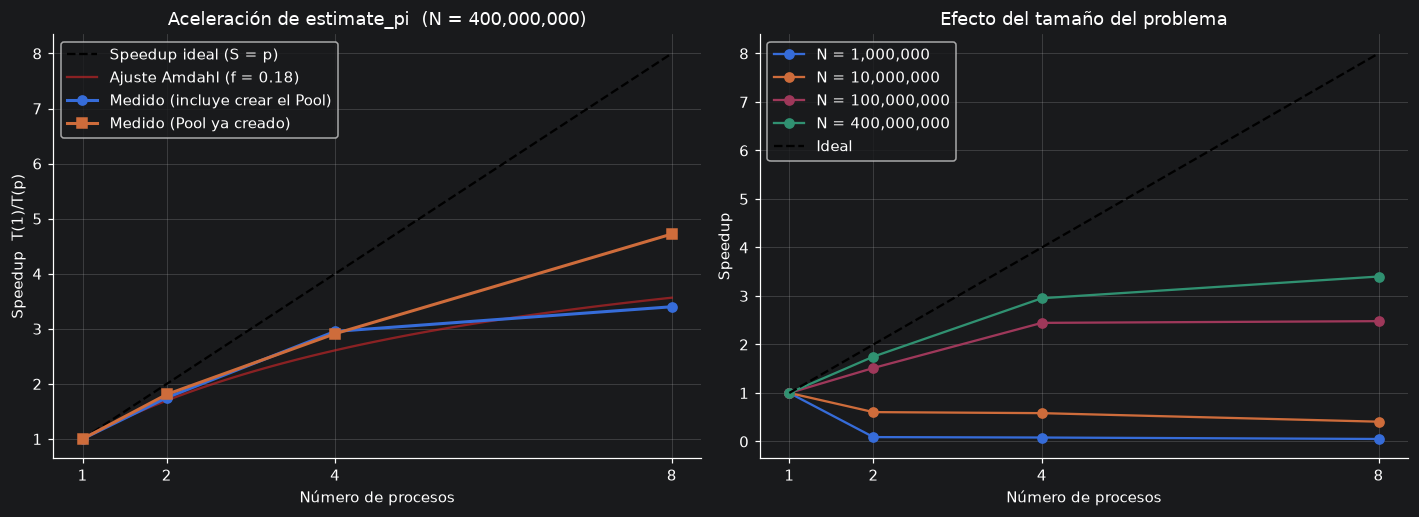

In [5]:
# Ajuste de la ley de Amdahl  S(p) = 1 / (f + (1-f)/p)  para el N mas grande (f = fraccion no paralelizable efectiva)
amdahl = lambda p, f: 1.0 / (f + (1.0 - f) / p)
big = df1[df1.N == max(N_LIST)]
(f_hat,), _ = curve_fit(amdahl, big.procesos, big.speedup_total, p0=[0.05], bounds=(0, 1))
print(f"Fraccion serial efectiva estimada (N={max(N_LIST):,}): f = {f_hat:.3f}  ->  speedup maximo teorico 1/f = {1/f_hat:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
pp = np.linspace(1, 8, 100)
ax[0].plot(pp, pp, "k--", label="Speedup ideal (S = p)")
ax[0].plot(pp, amdahl(pp, f_hat), color="tab:red", alpha=.6, label=f"Ajuste Amdahl (f = {f_hat:.2f})")
ax[0].plot(big.procesos, big.speedup_total, "o-", lw=2, label="Medido (incluye crear el Pool)")
ax[0].plot(big.procesos, big.speedup_pool_listo, "s-", lw=2, label="Medido (Pool ya creado)")
ax[0].set(xlabel="Número de procesos", ylabel="Speedup  T(1)/T(p)", xticks=PROCS,
          title=f"Aceleración de estimate_pi  (N = {max(N_LIST):,.0f})")
ax[0].legend()

for N in N_LIST:
    s = df1[df1.N == N]
    ax[1].plot(s.procesos, s.speedup_total, "o-", label=f"N = {N:,}")
ax[1].plot(pp, pp, "k--", label="Ideal")
ax[1].set(xlabel="Número de procesos", ylabel="Speedup", xticks=PROCS, title="Efecto del tamaño del problema")
ax[1].legend()
plt.tight_layout(); savefig("ej1_speedup"); plt.show()

In [6]:
# Cuanto cuesta solo arrancar el Pool (spawn de p procesos + import de numpy en cada uno)?
startup = {}
for p in [2, 4, 8]:
    ts = []
    for _ in range(5):
        t0 = time.perf_counter()
        with Pool(p) as pl: pl.map(count_inside, [(1, i) for i in range(p)])   # tarea trivial
        ts.append(time.perf_counter() - t0)
    startup[p] = np.median(ts)
print("Sobrecosto de arrancar un Pool (s):", {p: round(t, 3) for p, t in startup.items()})
print(f"Tiempo secuencial N={max(N_LIST):,} (s):", round(float(big.t_total.iloc[0]), 3))

Sobrecosto de arrancar un Pool (s): {2: np.float64(0.182), 4: np.float64(0.187), 8: np.float64(0.272)}
Tiempo secuencial N=400,000,000 (s): 2.771


### Análisis del Ejercicio 1

*(Resultados de la ejecución guardada en este notebook: N = 400 M, equipo con 10 CPUs lógicas. Los tiempos cambian un poco de una corrida a otra, pero el comportamiento es el mismo.)*

| Procesos | Speedup (con creación del Pool) | Speedup (Pool ya creado) | Ideal | Eficiencia S/p (con Pool) |
|---|---|---|---|---|
| 1 | 1.00 | 1.00 | 1 | 1.00 |
| 2 | 1.75 | 1.81 | 2 | 0.87 |
| 4 | 2.95 | 2.91 | 4 | 0.74 |
| 8 | 3.40 | 4.72 | 8 | 0.43 |

**¿Por qué no es lineal?** La curva queda siempre por debajo de la recta ideal por varias razones que se ven en los datos:

1. **Fracción serial y ley de Amdahl.** $S(p)=1/(f+(1-f)/p)$: lo que no se paraleliza (generar las tareas, crear los procesos, recolectar y sumar los conteos, `pool.map`, destruir el Pool) fija un techo $1/f$. Con el Pool incluido en el tiempo, el ajuste da $f\approx 0.18$ (techo $1/f\approx 5.6$×), y la curva de Amdahl se pega bien a los puntos medidos: con 8 procesos el modelo predice ≈ 3.6 y se midió 3.4.
2. **Sobrecosto de arranque (comunicación/sincronización de procesos).** Con *spawn*, cada proceso hijo es un intérprete nuevo que debe importar NumPy: arrancar el Pool cuesta ≈ 0.18 s (2 procesos), ≈ 0.19 s (4) y ≈ 0.27 s (8) — **crece con `p`**. Por eso, para $N$ pequeño ($10^6$–$10^7$, el cómputo secuencial dura menos de 0.1 s) el paralelo es *más lento* que el secuencial (speedup < 1: ≈ 0.05–0.4 para $N=10^6$ y $10^7$), y para $N=10^8$ se gana ≈ 2.5× con 8 procesos, frente a ≈ 3.4× con $N=4\times10^8$. La gráfica de la derecha muestra que el speedup mejora al crecer $N$ (ley de Gustafson: más trabajo útil amortiza la parte serial).
3. **Aun sin ese costo (Pool ya creado) el speedup con 8 procesos es ≈ 4.7, no 8.** Quedan: el reparto/recolección de resultados (serialización por *pickle*), el desbalance entre procesos (el tiempo lo manda el más lento: barrera implícita al final del `map`), la **competencia por recursos compartidos** (ancho de banda de memoria y caché; el generador pseudoaleatorio y los arreglos temporales de 2 M de elementos por proceso son intensivos en memoria) y que las CPUs lógicas **no son 8 núcleos idénticos** (en equipos con núcleos de rendimiento y de eficiencia, o con *hyper-threading*, los últimos procesos aportan menos que los primeros). La eficiencia $S/p$ cae de ≈ 0.87 (2 procesos) a ≈ 0.43 (8 procesos con Pool incluido).


---
## Ejercicio 2 — Mochila 0/1 voraz: menor peso primero vs. valor/peso

Se comparan dos heurísticas voraces (se recorre la lista ordenada y se agrega cada objeto que todavía quepa):

* **Valor/peso** (clásica): orden descendente por $v_i/w_i$.
* **Menor peso**: orden ascendente por $w_i$ (en empate, el de mayor valor).

Como referencia se calcula el **óptimo** con programación dinámica.

Instancia aleatoria: [('o1', 13, 52), ('o2', 5, 43), ('o3', 3, 36), ('o4', 12, 5), ('o5', 19, 41), ('o6', 12, 23), ('o7', 5, 52), ('o8', 19, 42), ('o9', 14, 18), ('o10', 10, 47), ('o11', 13, 10), ('o12', 4, 32)] | capacidad = 51


,Método,Objetos seleccionados,# objetos,Capacidad usada,Valor total,% del óptimo
0,Valor/peso,"o3, o7, o2, o12, o10, o1",6,40,262,100.0
1,Menor peso,"o3, o12, o7, o2, o10, o6, o4",7,51,238,90.8


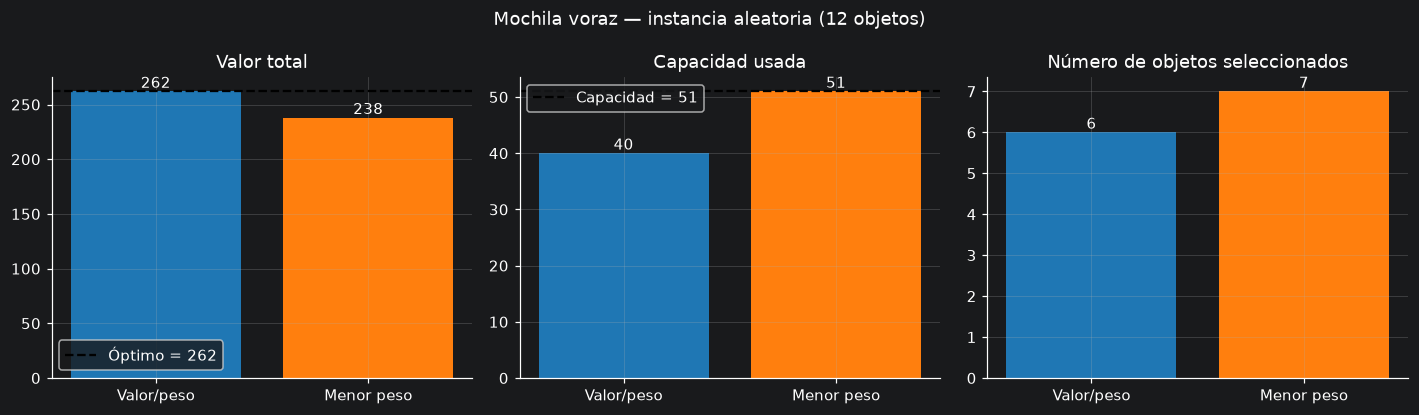

In [7]:
def greedy_knapsack(items, capacity, criterion):
    """items: lista de (nombre, peso, valor). criterion: 'ratio' o 'peso'."""
    key = (lambda it: -it[2] / it[1]) if criterion == "ratio" else (lambda it: (it[1], -it[2]))
    chosen, used, value = [], 0, 0
    for name, w, v in sorted(items, key=key):
        if used + w <= capacity:
            chosen.append(name); used += w; value += v
    return dict(objetos=chosen, capacidad_usada=used, valor_total=value)

def knapsack_dp(items, capacity):
    best = [0] * (capacity + 1)
    for _, w, v in items:
        for c in range(capacity, w - 1, -1):
            best[c] = max(best[c], best[c - w] + v)
    return best[capacity]

def compare_methods(items, capacity):
    res = {"Valor/peso": greedy_knapsack(items, capacity, "ratio"),
           "Menor peso": greedy_knapsack(items, capacity, "peso")}
    opt = knapsack_dp(items, capacity)
    df = pd.DataFrame({
        "Método": list(res),
        "Objetos seleccionados": [", ".join(map(str, r["objetos"])) for r in res.values()],
        "# objetos": [len(r["objetos"]) for r in res.values()],
        "Capacidad usada": [r["capacidad_usada"] for r in res.values()],
        "Valor total": [r["valor_total"] for r in res.values()],
    })
    df["% del óptimo"] = (100 * df["Valor total"] / opt).round(1)
    return df, opt

def plot_comparison(df, capacity, opt, title, fname):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    colors = ["tab:blue", "tab:orange"]
    ax[0].bar(df["Método"], df["Valor total"], color=colors); ax[0].axhline(opt, color="k", ls="--", label=f"Óptimo = {opt}")
    ax[0].set(title="Valor total"); ax[0].legend()
    ax[1].bar(df["Método"], df["Capacidad usada"], color=colors); ax[1].axhline(capacity, color="k", ls="--", label=f"Capacidad = {capacity}")
    ax[1].set(title="Capacidad usada"); ax[1].legend()
    ax[2].bar(df["Método"], df["# objetos"], color=colors); ax[2].set(title="Número de objetos seleccionados")
    for a in ax:
        for p in a.patches: a.annotate(f"{p.get_height():g}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
    fig.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

# --- (a) instancia aleatoria de 12 objetos (semilla elegida para que los dos criterios difieran) ---
rng = np.random.default_rng(SEED + 1)
items_rand = [(f"o{i+1}", int(w), int(v)) for i, (w, v) in enumerate(zip(rng.integers(2, 21, 12), rng.integers(5, 61, 12)))]
cap_rand = int(0.4 * sum(w for _, w, _ in items_rand))
print("Instancia aleatoria:", items_rand, "| capacidad =", cap_rand)
df2a, opt_a = compare_methods(items_rand, cap_rand)
display(df2a)
plot_comparison(df2a, cap_rand, opt_a, "Mochila voraz — instancia aleatoria (12 objetos)", "ej2_aleatoria")

### Entregable: instancia pequeña donde "menor peso" pierde frente a "valor/peso"

Idea: poner muchos objetos livianos pero casi sin valor que **ocupan la capacidad** y dejan fuera a un objeto pesado y muy valioso.
Con capacidad $W=10$: tres objetos livianos $A(2,1), B(3,1), C(4,1)$ (peso, valor) y un objeto pesado $D(10,100)$.

* Menor peso toma $A, B, C$ (peso 9, valor 3) y ya no cabe $D$.
* Valor/peso ordena $D$ (razón 10) antes que los demás y toma solo $D$ (peso 10, valor 100) — que además es el óptimo.

,Método,Objetos seleccionados,# objetos,Capacidad usada,Valor total,% del óptimo
0,Valor/peso,D,1,10,100,100.0
1,Menor peso,"A, B, C",3,9,3,3.0


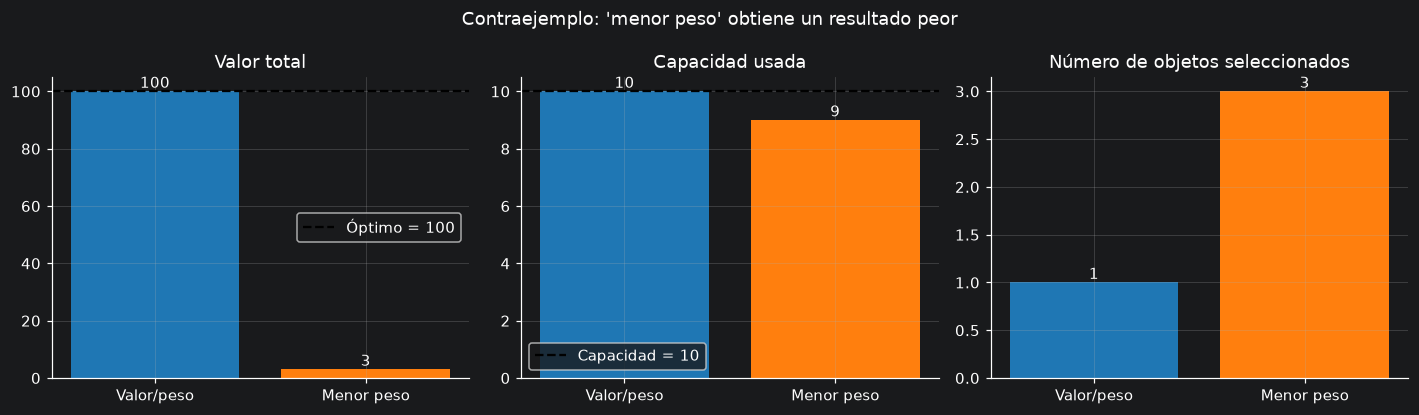

In [8]:
items_ce = [("A", 2, 1), ("B", 3, 1), ("C", 4, 1), ("D", 10, 100)]
cap_ce = 10
df2b, opt_b = compare_methods(items_ce, cap_ce)
display(df2b)
plot_comparison(df2b, cap_ce, opt_b, "Contraejemplo: 'menor peso' obtiene un resultado peor", "ej2_contraejemplo")
assert df2b.loc[df2b["Método"] == "Menor peso", "Valor total"].item() < df2b.loc[df2b["Método"] == "Valor/peso", "Valor total"].item()

In [9]:
# Complemento: que tan seguido pierde 'menor peso' en instancias aleatorias?
rng = np.random.default_rng(SEED + 100)
wins = {"ratio": 0, "peso": 0, "empate": 0}; gap = {"ratio": [], "peso": []}
for _ in range(2000):
    n = 12
    its = [(i, int(w), int(v)) for i, (w, v) in enumerate(zip(rng.integers(1, 31, n), rng.integers(1, 101, n)))]
    cap = int(0.4 * sum(w for _, w, _ in its)); opt = knapsack_dp(its, cap)
    vr, vp = (greedy_knapsack(its, cap, c)["valor_total"] for c in ("ratio", "peso"))
    wins["ratio" if vr > vp else "peso" if vp > vr else "empate"] += 1
    gap["ratio"].append(vr / opt); gap["peso"].append(vp / opt)
print("Victorias en 2000 instancias aleatorias:", wins)
print(f"Valor promedio / óptimo -> valor/peso: {np.mean(gap['ratio']):.3f} | menor peso: {np.mean(gap['peso']):.3f}")

Victorias en 2000 instancias aleatorias: {'ratio': 1673, 'peso': 16, 'empate': 311}
Valor promedio / óptimo -> valor/peso: 0.985 | menor peso: 0.843


### Análisis del Ejercicio 2

**Resultados.**
* *Instancia aleatoria (12 objetos, capacidad 51):* valor/peso elige 6 objetos (peso 40, valor **262** = óptimo); menor peso elige 7 objetos, llena la mochila por completo (peso 51) pero obtiene valor **238** (90.8 % del óptimo). Es decir, "meter más cosas" o "usar toda la capacidad" no implica más valor.
* *Contraejemplo diseñado* ($W=10$; $A(2,1),B(3,1),C(4,1),D(10,100)$): menor peso toma $A,B,C$ → valor **3**; valor/peso toma $D$ → valor **100** (óptimo). Menor peso obtiene solo el 3 % del óptimo, y la razón puede hacerse arbitrariamente mala aumentando el valor de $D$.
* *Complemento (2000 instancias aleatorias):* valor/peso gana en 1673, menor peso en solo 16 y hay 311 empates; el valor promedio relativo al óptimo es 0.985 vs. 0.843.

**Conclusión.** El criterio de menor peso ignora por completo el valor: solo optimiza el *número* de objetos, que es la métrica correcta únicamente si todos los valores fueran iguales. Valor/peso mide el "rendimiento por unidad de capacidad", que es justo lo que se está gastando, y por eso es mucho más robusto (aunque tampoco garantiza el óptimo en la mochila 0/1).


---
## Ejercicio 3 — Búsqueda local 2-opt para el TSP

**2-opt:** dado un tour, se eliminan dos aristas $(a,b)$ y $(c,d)$ y se reconectan como $(a,c)$ y $(b,d)$ (equivale a invertir el segmento $b\ldots c$).
Si el cambio reduce el costo, se aplica; se repite hasta que ninguna pareja de aristas mejore (óptimo local).
La implementación (celda de utilidades) evalúa todos los pares con NumPy y cuenta **cada movimiento aplicado** como una "mejora".

**Experimento:** 100 instancias aleatorias de 50 ciudades en $[0,1]^2$. En cada instancia (comparación pareada) se parte de
(1) un tour aleatorio y (2) Vecino Más Cercano desde un nodo inicial aleatorio. Se usa la estrategia *first-improvement*;
como chequeo de robustez se repite con *best-improvement*.

In [10]:
N3, INST3 = 50, 100
rows, curves = [], {}
for strategy in ["first", "best"]:
    for s in range(INST3):
        rng = np.random.default_rng(1000 + s)
        D = dist_matrix(rng.random((N3, 2)))
        inits = {"Aleatoria": rng.permutation(N3), "Vecino más cercano": nearest_neighbor(D, int(rng.integers(N3)))}
        for name, init in inits.items():
            t, imp, hist = two_opt(init, D, strategy)
            assert sorted(t) == list(range(N3))
            rows.append(dict(estrategia=strategy, instancia=s, inicio=name, costo_inicial=hist[0], mejoras=imp, costo_final=hist[-1]))
            if s == 0 and strategy == "first": curves[name] = hist
df3 = pd.DataFrame(rows)
summary3 = df3.groupby(["estrategia", "inicio"])[["costo_inicial", "mejoras", "costo_final"]].agg(["mean", "std"]).round(3)
display(summary3)

costo_inicial        mejoras          \
                                       mean    std    mean     std   
estrategia inicio                                                    
best       Aleatoria                 25.953  1.916   45.28   3.599   
           Vecino más cercano         7.073  0.591   10.46   3.242   
first      Aleatoria                 25.953  1.916  145.39  13.903   
           Vecino más cercano         7.073  0.591   18.52   7.640   

                              costo_final         
                                     mean    std  
estrategia inicio                                 
best       Aleatoria                6.052  0.325  
           Vecino más cercano       5.917  0.298  
first      Aleatoria                6.043  0.332  
           Vecino más cercano       6.030  0.332

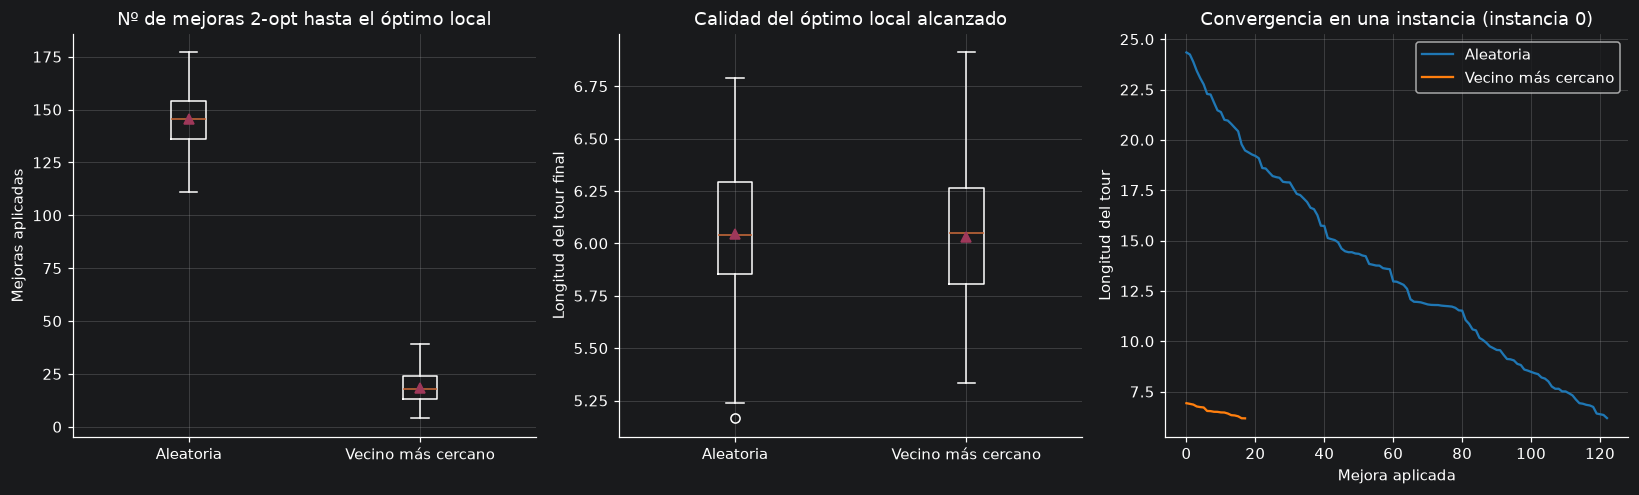

[first] mejoras: aleatoria=145.4  NN=18.5  (p=3.87e-18) | costo final: aleatoria=6.043  NN=6.030  (p=8.58e-01) | NN mejor en costo en 51% de las instancias
[best] mejoras: aleatoria=45.3  NN=10.5  (p=3.70e-18) | costo final: aleatoria=6.052  NN=5.917  (p=6.48e-08) | NN mejor en costo en 72% de las instancias


In [11]:
d1 = df3[df3.estrategia == "first"]
order = ["Aleatoria", "Vecino más cercano"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].boxplot([d1[d1.inicio == k].mejoras for k in order], tick_labels=order, showmeans=True)
ax[0].set(title="Nº de mejoras 2-opt hasta el óptimo local", ylabel="Mejoras aplicadas")
ax[1].boxplot([d1[d1.inicio == k].costo_final for k in order], tick_labels=order, showmeans=True)
ax[1].set(title="Calidad del óptimo local alcanzado", ylabel="Longitud del tour final")
for k, c in zip(order, ["tab:blue", "tab:orange"]):
    ax[2].plot(curves[k], color=c, label=k)
ax[2].set(title="Convergencia en una instancia (instancia 0)", xlabel="Mejora aplicada", ylabel="Longitud del tour"); ax[2].legend()
plt.tight_layout(); savefig("ej3_2opt"); plt.show()

# Pruebas pareadas (Wilcoxon) sobre las 100 instancias
for strategy in ["first", "best"]:
    a = df3[(df3.estrategia == strategy) & (df3.inicio == "Aleatoria")].set_index("instancia")
    b = df3[(df3.estrategia == strategy) & (df3.inicio == "Vecino más cercano")].set_index("instancia")
    w_imp = stats.wilcoxon(a.mejoras, b.mejoras); w_cost = stats.wilcoxon(a.costo_final, b.costo_final)
    print(f"[{strategy}] mejoras: aleatoria={a.mejoras.mean():.1f}  NN={b.mejoras.mean():.1f}  (p={w_imp.pvalue:.2e}) | "
          f"costo final: aleatoria={a.costo_final.mean():.3f}  NN={b.costo_final.mean():.3f}  (p={w_cost.pvalue:.2e}) | "
          f"NN mejor en costo en {(b.costo_final < a.costo_final).mean()*100:.0f}% de las instancias")

### Análisis del Ejercicio 3

**Sí: el Vecino Más Cercano (NN) converge con muchas menos mejoras.** (50 ciudades, 100 instancias, comparación pareada.)

| Estrategia | Inicio | Costo inicial | Nº de mejoras | Costo final |
|---|---|---|---|---|
| first-improvement | Aleatorio | 25.95 | **145.4** | 6.043 |
| first-improvement | NN | 7.07 | **18.5** | 6.030 |
| best-improvement | Aleatorio | 25.95 | **45.3** | 6.052 |
| best-improvement | NN | 7.07 | **10.5** | 5.917 |

* **Número de mejoras:** el diagrama de cajas muestra que ni siquiera se traslapan las distribuciones (≈ 111–177 mejoras vs. ≈ 4–39); NN necesita ≈ 8× menos mejoras con *first-improvement* y ≈ 4× menos con *best-improvement* (Wilcoxon pareado, $p\approx 10^{-18}$ en ambos casos). La curva de convergencia de la instancia 0 lo ilustra: el tour aleatorio empieza en ≈ 24 y debe descender por más de 120 movimientos, mientras que NN ya arranca en ≈ 7 y termina en unos 18.
* **¿Por qué?** 2-opt solo repara cruces/aristas largas; un tour aleatorio tiene ≈ 4× el costo final, así que cada mejora recorta poco y hacen falta muchas, mientras que NN ya construyó un tour "casi bueno" y solo restan unos pocos defectos (típicamente las últimas aristas largas con las que NN cierra el ciclo).
* **Calidad del óptimo:** con *first-improvement* los costos finales son prácticamente iguales (6.043 vs. 6.030; $p=0.86$, sin diferencia significativa; las cajas casi coinciden). Con *best-improvement* NN sí es mejor (5.917 vs. 6.052, ≈ 2 %, $p\approx 10^{-7}$, mejor en 72 % de las instancias). En ningún caso es peor.
* **Conclusión:** NN reduce drásticamente el trabajo de 2-opt y, a lo sumo, mejora ligeramente la calidad del óptimo local; ambos caen en óptimos locales: en la instancia de 50 ciudades del ejercicio 4, 2-opt desde aleatorio promedia 6.05 contra un mejor conocido de 5.80 (≈ 4 % más), por lo que 2-opt por sí solo no garantiza llegar al óptimo.


---
## Ejercicio 4 — Recocido Simulado (Simulated Annealing) con 2-opt

* **Solución inicial:** tour aleatorio. **Movimiento:** 2-opt aleatorio (se elige un par $i<j$ y se invierte el segmento).
* **Aceptación (Metropolis):** si $\Delta<0$ se acepta; si no, con probabilidad $e^{-\Delta/T}$.
* **Esquemas de enfriamiento** (todos van de $T_0$ a $T_f$ en exactamente $K$ iteraciones, para que la comparación sea justa):

| Esquema | $T(k)$ |
|---|---|
| Lineal | $T_0 + (T_f - T_0)\,k/(K-1)$ |
| Exponencial (geométrico) | $T_0\,(T_f/T_0)^{k/(K-1)}$ |
| Logarítmico | $T_0 / (1 + \alpha \ln(1+k))$ |
| Inverso (rápido) | $T_0 / (1 + \beta k)$ |

$T_0 = 0.5\,\bar d$ y $T_f = 0.01\,\bar d$, con $\bar d$ la distancia promedio entre ciudades (escala natural de los $\Delta$).

In [12]:
SCHEDULES = ["lineal", "exponencial", "logarítmico", "inverso"]

def temperatures(name, T0, Tf, K):
    k = np.arange(K)
    if name == "lineal":      return T0 + (Tf - T0) * k / (K - 1)
    if name == "exponencial": return T0 * (Tf / T0) ** (k / (K - 1))
    if name == "logarítmico":
        alpha = (T0 / Tf - 1) / math.log(K);  return T0 / (1 + alpha * np.log1p(k))
    if name == "inverso":
        beta = (T0 / Tf - 1) / (K - 1);       return T0 / (1 + beta * k)
    raise ValueError(name)

def default_temps(D):
    dbar = D[D > 0].mean()
    return 0.5 * dbar, 0.01 * dbar

def simulated_annealing(D, schedule, n_iter, T0, Tf, seed, record_every=0, init=None):
    rnd = random.Random(seed); n = len(D); Dl = D.tolist()
    T = temperatures(schedule, T0, Tf, n_iter).tolist()
    tour = list(init) if init is not None else rnd.sample(range(n), n)
    cost = sum(Dl[tour[i]][tour[(i + 1) % n]] for i in range(n))
    best, best_tour = cost, tour[:]
    rec_it, rec_cost, rec_best = [], [], []
    t0 = time.perf_counter()
    for k in range(n_iter):
        while True:                                   # par (i, j) valido para 2-opt
            i = rnd.randrange(n - 2); j = rnd.randrange(i + 2, n)
            if not (i == 0 and j == n - 1): break
        a, b, c, d = tour[i], tour[i + 1], tour[j], tour[(j + 1) % n]
        delta = Dl[a][c] + Dl[b][d] - Dl[a][b] - Dl[c][d]
        if delta < 0 or rnd.random() < math.exp(-delta / T[k]):
            tour[i + 1:j + 1] = tour[i + 1:j + 1][::-1]
            cost += delta
            if cost < best - 1e-12: best, best_tour = cost, tour[:]
        if record_every and k % record_every == 0:
            rec_it.append(k); rec_cost.append(cost); rec_best.append(best)
    elapsed = time.perf_counter() - t0
    best = tour_length(best_tour, D)                  # recalcula (evita deriva numerica)
    return dict(best=best, tour=best_tour, time=elapsed, it=rec_it, cost=rec_cost, best_curve=rec_best, T=T)

# Instancia fija de 50 ciudades para los experimentos de SA
rng = np.random.default_rng(SEED)
pts4 = rng.random((50, 2)); D4 = dist_matrix(pts4); T0_4, Tf_4 = default_temps(D4)
print(f"T0 = {T0_4:.3f}, Tf = {Tf_4:.4f}")

T0 = 0.260, Tf = 0.0052


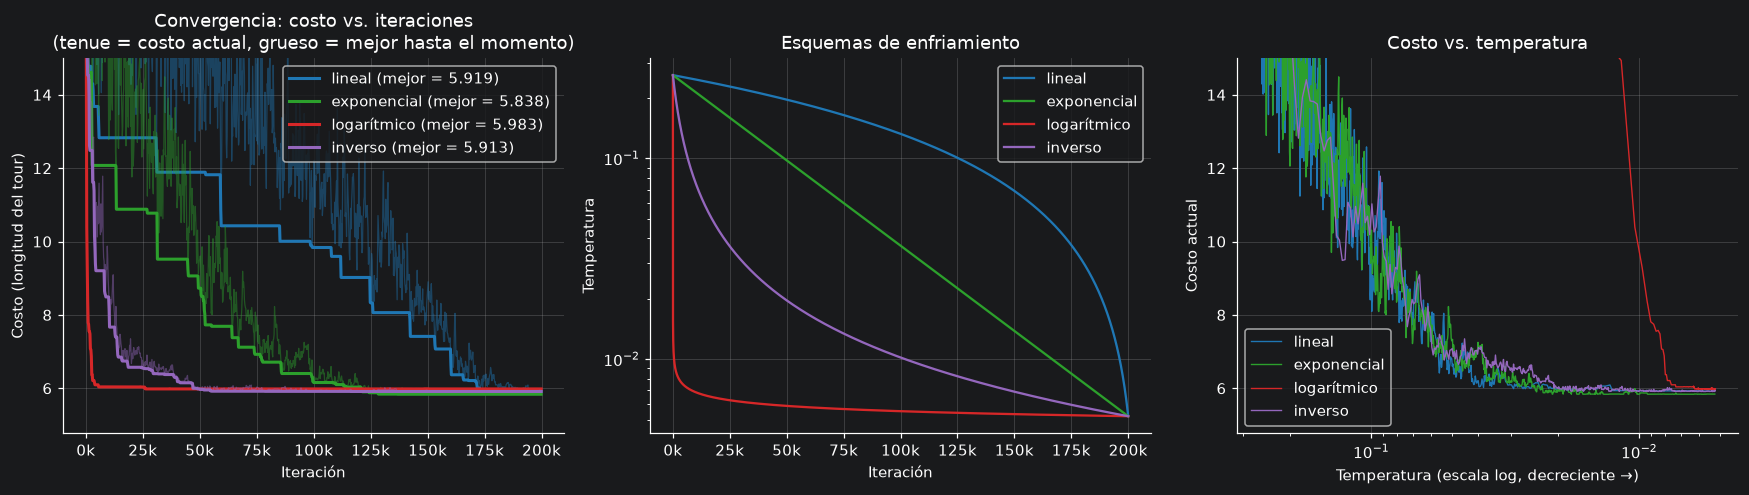

In [13]:
# (1) Curvas de convergencia: una corrida de K = 200,000 iteraciones por esquema (misma semilla / misma solución inicial)
K_CURVE = 200_000
runs = {s: simulated_annealing(D4, s, K_CURVE, T0_4, Tf_4, seed=7, record_every=200) for s in SCHEDULES}
colors = dict(zip(SCHEDULES, ["tab:blue", "tab:green", "tab:red", "tab:purple"]))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for s, r in runs.items():
    ax[0].plot(r["it"], r["cost"], color=colors[s], alpha=.45, lw=.8)
    ax[0].plot(r["it"], r["best_curve"], color=colors[s], lw=2, label=f"{s} (mejor = {r['best']:.3f})")
ax[0].set(xlabel="Iteración", ylabel="Costo (longitud del tour)", title="Convergencia: costo vs. iteraciones\n(tenue = costo actual, grueso = mejor hasta el momento)")
ax[0].legend(); ax[0].set_ylim(top=D4.shape[0] * 0.3)
kfmt = plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
ax[0].xaxis.set_major_formatter(kfmt)
for s, r in runs.items():
    ax[1].plot(r["T"], color=colors[s], label=s)
ax[1].set(xlabel="Iteración", ylabel="Temperatura", yscale="log", title="Esquemas de enfriamiento"); ax[1].xaxis.set_major_formatter(kfmt); ax[1].legend()
for s, r in runs.items():
    ax[2].plot(np.array(r["T"])[r["it"]], r["cost"], color=colors[s], lw=.9, label=s)
ax[2].set(xlabel="Temperatura (escala log, decreciente →)", ylabel="Costo actual", xscale="log", title="Costo vs. temperatura")
ax[2].invert_xaxis(); ax[2].legend(); ax[2].set_ylim(top=D4.shape[0] * 0.3)
plt.tight_layout(); savefig("ej4_convergencia"); plt.show()

Mejor costo conocido en esta instancia: 5.8013 | 2-opt (arranque aleatorio): media 6.055, 3.3 ms por corrida


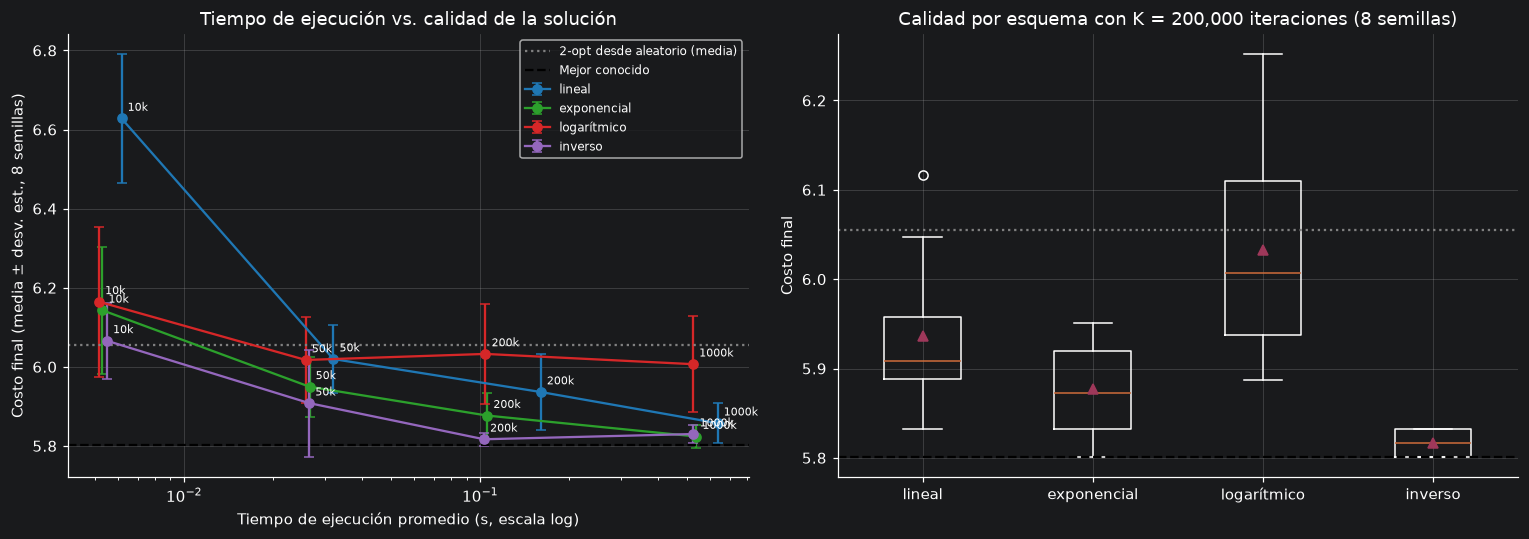

costo                            gap_vs_mejor          \
esquema     exponencial inverso lineal logarítmico  exponencial inverso   
iteraciones                                                               
10000             6.143   6.066  6.628       6.164         5.89    4.56   
50000             5.950   5.908  6.020       6.017         2.56    1.84   
200000            5.877   5.817  5.936       6.033         1.30    0.27   
1000000           5.824   5.830  5.858       6.007         0.39    0.50   

                                    tiempo                             
esquema     lineal logarítmico exponencial inverso lineal logarítmico  
iteraciones                                                            
10000        14.25        6.26       0.005   0.005  0.006       0.005  
50000         3.76        3.73       0.027   0.026  0.032       0.026  
200000        2.33        3.99       0.106   0.103  0.160       0.104  
1000000       0.97        3.54       0.538   0.526  0.634       0.524

In [14]:
# (2) Tiempo de ejecución vs. calidad: 4 presupuestos de iteraciones x 4 esquemas x 8 semillas
BUDGETS = [10_000, 50_000, 200_000, 1_000_000]
SEEDS4 = range(8)
rows = []
for s in SCHEDULES:
    for K in BUDGETS:
        for sd in SEEDS4:
            r = simulated_annealing(D4, s, K, T0_4, Tf_4, seed=100 + sd)
            rows.append(dict(esquema=s, iteraciones=K, semilla=sd, costo=r["best"], tiempo=r["time"]))
df4 = pd.DataFrame(rows)

# Referencia: 2-opt multi-arranque (30 arranques aleatorios) sobre la misma instancia
rng_ref = np.random.default_rng(99)
ref = []
t0 = time.perf_counter()
for _ in range(30):
    t, _, h = two_opt(rng_ref.permutation(50), D4); ref.append(h[-1])
t_ref = (time.perf_counter() - t0) / 30
best_known = min(df4.costo.min(), min(ref))
print(f"Mejor costo conocido en esta instancia: {best_known:.4f} | 2-opt (arranque aleatorio): media {np.mean(ref):.3f}, {t_ref*1000:.1f} ms por corrida")

agg = df4.groupby(["esquema", "iteraciones"]).agg(costo=("costo", "mean"), costo_sd=("costo", "std"), tiempo=("tiempo", "mean")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for s in SCHEDULES:
    a = agg[agg.esquema == s]
    ax[0].errorbar(a.tiempo, a.costo, yerr=a.costo_sd, fmt="o-", color=colors[s], capsize=3, label=s)
    for _, row in a.iterrows():
        ax[0].annotate(f"{int(row.iteraciones/1000)}k", (row.tiempo, row.costo), textcoords="offset points", xytext=(4, 5), fontsize=7)
ax[0].axhline(np.mean(ref), color="gray", ls=":", label="2-opt desde aleatorio (media)")
ax[0].axhline(best_known, color="k", ls="--", label="Mejor conocido")
ax[0].set(xscale="log", xlabel="Tiempo de ejecución promedio (s, escala log)", ylabel="Costo final (media ± desv. est., 8 semillas)",
          title="Tiempo de ejecución vs. calidad de la solución"); ax[0].legend(fontsize=8)

K_BAR = BUDGETS[-2]
sub = df4[df4.iteraciones == K_BAR]
ax[1].boxplot([sub[sub.esquema == s].costo for s in SCHEDULES], tick_labels=SCHEDULES, showmeans=True)
ax[1].axhline(best_known, color="k", ls="--"); ax[1].axhline(np.mean(ref), color="gray", ls=":")
ax[1].set(ylabel="Costo final", title=f"Calidad por esquema con K = {K_BAR:,} iteraciones (8 semillas)")
plt.tight_layout(); savefig("ej4_tiempo_vs_calidad"); plt.show()

tabla = agg.assign(gap_vs_mejor=lambda d: (100 * (d.costo / best_known - 1)).round(2)).round({"costo": 3, "costo_sd": 3, "tiempo": 3})
display(tabla.pivot(index="iteraciones", columns="esquema", values=["costo", "gap_vs_mejor", "tiempo"]))

### Análisis del Ejercicio 4

*(Instancia fija de 50 ciudades; mejor costo conocido = 5.80; 2-opt desde aleatorio promedia 6.05 en ≈ 3 ms.)*

**Convergencia.** Con el mismo número de iteraciones, el esquema determina *cuándo* se "congela" el sistema:
* **Exponencial:** la temperatura baja a ritmo constante en escala log; el costo desciende de forma sostenida y la fase de refinamiento final ocurre a baja temperatura. Es el que alcanza el mejor costo con 200 k iteraciones en la curva (5.84) y el de menor dispersión entre semillas en presupuestos grandes.
* **Lineal:** permanece a temperaturas altas gran parte de la corrida (en escala log la temperatura cae de golpe al final), por lo que explora mucho pero le queda poco tiempo "frío" para refinar; con presupuestos pequeños es el peor (10 k iteraciones: 6.63 ≈ 14 % sobre el mejor conocido) y mejora al crecer el presupuesto (5.86 con 1 M).
* **Inverso (1/k):** enfría muy rápido al inicio y dedica la mayor parte de las iteraciones a baja temperatura. Es el mejor con presupuestos pequeños/medianos (6.07 con 10 k; 5.82 con 200 k).
* **Logarítmico** (parametrizado para llegar a $T_f$ en $K$ iteraciones, la forma $T_0/(1+\alpha\ln(1+k))$ cae casi instantáneamente a $\approx T_f$): funciona como un *quench* (templado brusco): converge rapidísimo pero se queda atrapado en óptimos locales (≈ 6.0 aunque se le dé 1 M de iteraciones; ≈ 3.5 % sobre el mejor conocido). Es el peor y el que menos mejora con más tiempo.

**Tiempo vs. calidad.** El tiempo por iteración es casi igual en tres de los cuatro esquemas y algo mayor en el lineal (≈ 0.5–0.6 s por millón de iteraciones; con 1 M de iteraciones exponencial, inverso y logarítmico tardan ≈ 0.52–0.54 s y lineal ≈ 0.63 s, es decir ≈ 20 % más; con 200 k, ≈ 0.10 s contra ≈ 0.16 s. El esquema lineal es más lento probablemente porque pasa más tiempo caliente, acepta más movimientos y por tanto hace más inversiones de segmentos), porque el costo base de una iteración (evaluar Δ y a veces invertir un segmento) no depende del cálculo de la temperatura. Por eso **el tiempo lo fija el número de iteraciones, y el esquema decide cuánta calidad se obtiene por ese tiempo**: la gráfica muestra que con ≈ 0.1 s (200 k iteraciones) inverso y exponencial ya superan al promedio de 2-opt y quedan a 0.3–1.3 % del mejor conocido; con ≈ 0.5 s (1 M) exponencial (+0.4 %) e inverso (+0.5 %) quedan prácticamente empatados, lineal en +1 % y logarítmico en +3.5 %. Aumentar 5× el presupuesto da rendimientos decrecientes (de 200 k a 1 M mejora solo ≈ 0.1–0.3 %). Frente a 2-opt (3 ms por corrida, costo medio 6.05) SA cuesta ≈ 30–160× más tiempo pero obtiene soluciones ≈ 3–4 % mejores.

**Conclusión.** El esquema de enfriamiento cambia poco el tiempo de cómputo por iteración (solo el lineal es algo más lento), pero sí cambia mucho la calidad por iteración. Con presupuestos grandes los esquemas geométrico (exponencial) e inverso son los mejores; con presupuestos pequeños conviene enfriar rápido (inverso); y un enfriamiento demasiado brusco (logarítmico aquí) o demasiado lento (lineal con pocas iteraciones) desperdicia el presupuesto.


---
## Ejercicio 5 — Razón de aproximación del algoritmo basado en MST

**Algoritmo (2-aproximación para TSP métrico):** (1) calcular el árbol de expansión mínima (Prim), (2) recorrerlo en preorden
(DFS) desde la ciudad 0, (3) atajar las ciudades repetidas. Con distancias euclidianas (desigualdad triangular) se cumple
$C_{MST} \le 2\,C^*$, ya que $\text{costo(MST)} \le C^*$ y el recorrido completo del árbol cuesta $2\cdot\text{costo(MST)}$.

El **óptimo** $C^*$ de cada instancia de 9 ciudades se calcula exactamente con Held–Karp (programación dinámica, $O(n^2 2^n)$).
Se comparan: MST puro, MST + 2-opt, 2-opt desde aleatorio, 2-opt desde Vecino Más Cercano y Recocido Simulado
(esquema exponencial, 20,000 iteraciones, inicio aleatorio).

In [15]:
def mst_tour(D):
    n = len(D)
    in_tree = np.zeros(n, bool); in_tree[0] = True
    key = D[0].copy(); parent = np.zeros(n, int)
    children = {i: [] for i in range(n)}
    for _ in range(n - 1):
        k = np.where(in_tree, np.inf, key); v = int(np.argmin(k))
        in_tree[v] = True; children[int(parent[v])].append(v)
        upd = (~in_tree) & (D[v] < key); key[upd] = D[v][upd]; parent[upd] = v
    tour, stack = [], [0]                              # preorden (DFS)
    while stack:
        u = stack.pop(); tour.append(u); stack.extend(reversed(children[u]))
    return np.array(tour)

def held_karp(D):
    n = len(D); Dl = D.tolist(); m = n - 1; INF = float("inf")
    dp = [[INF] * m for _ in range(1 << m)]
    for j in range(m): dp[1 << j][j] = Dl[0][j + 1]
    for mask in range(1, 1 << m):
        for j in range(m):
            cur = dp[mask][j]
            if cur == INF or not (mask >> j) & 1: continue
            for k in range(m):
                if (mask >> k) & 1: continue
                nm = mask | (1 << k); v = cur + Dl[j + 1][k + 1]
                if v < dp[nm][k]: dp[nm][k] = v
    return min(dp[-1][j] + Dl[j + 1][0] for j in range(m))

# validacion de Held-Karp contra fuerza bruta en una instancia pequeña
_D = dist_matrix(np.random.default_rng(0).random((8, 2)))
brute = min(tour_length((0,) + p, _D) for p in itertools.permutations(range(1, 8)))
assert abs(brute - held_karp(_D)) < 1e-9
print("Held-Karp validado contra fuerza bruta:", round(brute, 6))

Held-Karp validado contra fuerza bruta: 3.204471


In [16]:
N5, INST5 = 9, 100
rows = []
for s in range(INST5):
    rng = np.random.default_rng(5000 + s)
    D = dist_matrix(rng.random((N5, 2)))
    opt = held_karp(D)
    t_mst = mst_tour(D); c_mst = tour_length(t_mst, D)
    t_mst2, _, _ = two_opt(t_mst, D); c_mst2 = tour_length(t_mst2, D)
    c_ls_rand = two_opt(rng.permutation(N5), D)[2][-1]
    c_ls_nn = two_opt(nearest_neighbor(D, int(rng.integers(N5))), D)[2][-1]
    T0, Tf = default_temps(D)
    c_sa = simulated_annealing(D, "exponencial", 20_000, T0, Tf, seed=s)["best"]
    rows.append({"instancia": s, "óptimo": opt, "MST": c_mst, "MST + 2-opt": c_mst2,
                 "2-opt (aleatorio)": c_ls_rand, "2-opt (NN)": c_ls_nn, "Recocido Simulado": c_sa})
df5 = pd.DataFrame(rows).set_index("instancia")
methods5 = ["MST", "MST + 2-opt", "2-opt (aleatorio)", "2-opt (NN)", "Recocido Simulado"]
ratio5 = df5[methods5].div(df5["óptimo"], axis=0)
assert (ratio5.values >= 1 - 1e-9).all() and (ratio5["MST"] <= 2 + 1e-9).all()

resumen5 = pd.DataFrame({
    "razón media": ratio5.mean(), "razón mediana": ratio5.median(), "razón máx.": ratio5.max(),
    "% instancias óptimas": (ratio5 < 1 + 1e-9).mean() * 100}).round(3)
display(resumen5)

,razón media,razón mediana,razón máx.,% instancias óptimas
MST,1.143,1.133,1.400,4.0
MST + 2-opt,1.006,1.000,1.102,78.0
2-opt (aleatorio),1.007,1.000,1.161,77.0
2-opt (NN),1.006,1.000,1.078,79.0
Recocido Simulado,1.000,1.000,1.000,100.0


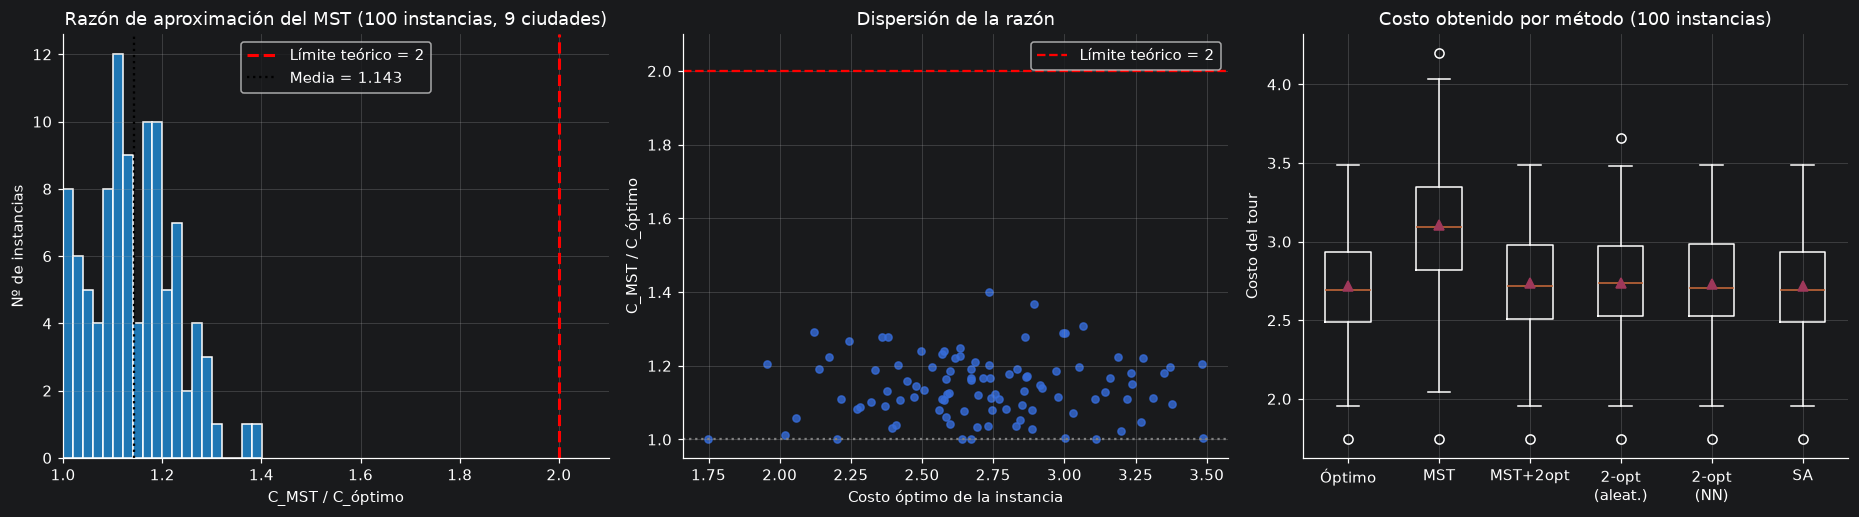

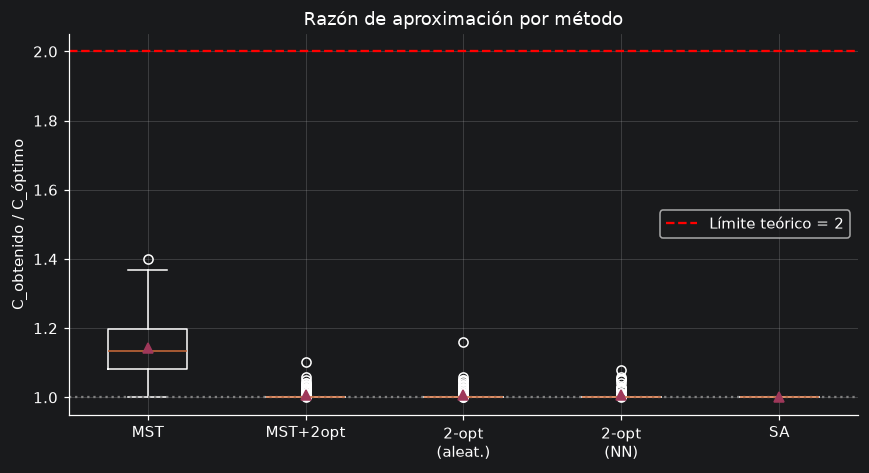

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
r = ratio5["MST"]
ax[0].hist(r, bins=20, color="tab:blue", edgecolor="white")
ax[0].axvline(2, color="red", ls="--", lw=2, label="Límite teórico = 2")
ax[0].axvline(r.mean(), color="k", ls=":", label=f"Media = {r.mean():.3f}")
ax[0].set(xlim=(1, 2.1), xlabel="C_MST / C_óptimo", ylabel="Nº de instancias", title="Razón de aproximación del MST (100 instancias, 9 ciudades)"); ax[0].legend()

ax[1].scatter(df5["óptimo"], r, s=22, alpha=.8)
ax[1].axhline(2, color="red", ls="--", label="Límite teórico = 2"); ax[1].axhline(1, color="gray", ls=":")
ax[1].set(ylim=(0.95, 2.1), xlabel="Costo óptimo de la instancia", ylabel="C_MST / C_óptimo", title="Dispersión de la razón"); ax[1].legend()

cols = ["óptimo"] + methods5
ax[2].boxplot([df5[c] for c in cols], tick_labels=["Óptimo", "MST", "MST+2opt", "2-opt\n(aleat.)", "2-opt\n(NN)", "SA"], showmeans=True)
ax[2].set(ylabel="Costo del tour", title="Costo obtenido por método (100 instancias)")
plt.tight_layout(); savefig("ej5_razon_y_comparacion"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.boxplot([ratio5[c] for c in methods5], tick_labels=["MST", "MST+2opt", "2-opt\n(aleat.)", "2-opt\n(NN)", "SA"], showmeans=True)
ax.axhline(1, color="gray", ls=":"); ax.axhline(2, color="red", ls="--", label="Límite teórico = 2")
ax.set(ylabel="C_obtenido / C_óptimo", title="Razón de aproximación por método"); ax.legend()
plt.tight_layout(); savefig("ej5_razones_por_metodo"); plt.show()

### Análisis del Ejercicio 5

**Razón observada vs. límite teórico (100 instancias de 9 ciudades, óptimo exacto con Held–Karp).**

| Método | Razón media | Mediana | Máxima | % instancias óptimas |
|---|---|---|---|---|
| MST | 1.143 | 1.133 | **1.400** | 4 % |
| MST + 2-opt | 1.006 | 1.000 | 1.102 | 78 % |
| 2-opt (inicio aleatorio) | 1.007 | 1.000 | 1.161 | 77 % |
| 2-opt (inicio NN) | 1.006 | 1.000 | 1.078 | 79 % |
| Recocido Simulado | 1.000 | 1.000 | 1.000 | 100 % |

* **¿Qué tan cerca del 2?** Muy lejos: la razón media es 1.14 y el peor caso de las 100 instancias es 1.40, es decir, el tour del MST cuesta en promedio ≈ 14 % más que el óptimo y nunca superó ≈ 40 % más (el histograma está concentrado en 1.0–1.3, con la línea de 2 totalmente aislada; la dispersión no muestra relación con el costo óptimo de la instancia). La cota de 2 es de **peor caso** y se alcanza solo con instancias construidas adversarialmente (el doble recorrido del árbol casi sin atajos útiles); en puntos euclidianos aleatorios el árbol mínimo ya es una muy buena aproximación del óptimo ($C_{MST}\le C^*$) y los atajos (desigualdad triangular) recortan aún más. Con solo 9 ciudades además hay poco espacio para que el recorrido se degrade.
* **Impacto de 2-opt como post-procesamiento:** es enorme. La razón media baja de 1.143 a 1.006 y el máximo de 1.40 a 1.10; en 78 % de las instancias el resultado es ya el óptimo (vs. 4 % del MST puro). El costo adicional de 2-opt es mínimo (milisegundos).
* **Frente a los experimentos anteriores:** MST+2-opt (1.006) es prácticamente equivalente a 2-opt desde NN (1.006) y a 2-opt desde un tour aleatorio (1.007), aunque este último tiene un peor caso mayor (1.16 vs. 1.10): usar un buen punto de partida evita las peores corridas (resultado coherente con el ejercicio 3, donde un buen arranque reduce el esfuerzo y mejora marginalmente la calidad), con la ventaja adicional de que MST aporta una **garantía** (≤ 2) antes de la mejora local, y 2-opt solo puede mejorarla. Sin embargo, el único método que encontró el óptimo en las 100 instancias fue el Recocido Simulado (con 20 000 iteraciones para 9 ciudades, que es mucho presupuesto): 2-opt, sea cual sea el inicio, queda atrapado en un óptimo local en ≈ 21–23 % de las instancias. En resumen: MST da garantía, 2-opt da calidad barata, y SA da calidad casi óptima a un costo de cómputo mayor.
